# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

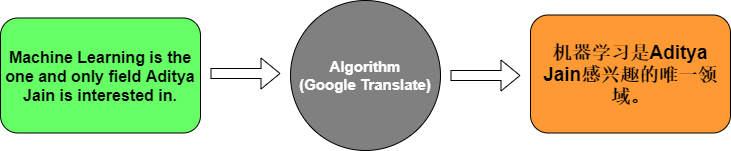

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [11]:
#!pip install tensorflow

In [5]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [6]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [7]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [8]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [9]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.0000e+00 - loss: 2.4891 - val_accuracy: 0.0000e+00 - val_loss: 2.4872
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.5714 - loss: 2.4799 - val_accuracy: 0.0000e+00 - val_loss: 2.4894
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.5714 - loss: 2.4709 - val_accuracy: 0.0000e+00 - val_loss: 2.4917
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.5714 - loss: 2.4615 - val_accuracy: 0.0000e+00 - val_loss: 2.4943
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.5714 - loss: 2.4514 - val_accuracy: 0.0000e+00 - val_loss: 2.4971
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.5714 - loss: 2.4402 - val_accuracy: 0.0000e+00 - val_loss: 2.5003
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.5714 - loss: 2.4274 - val_accuracy: 0.0000e+00 - val_loss: 2.5040
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5714 - loss: 2.4126 - val_accu

In [11]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. It converts numerical word indexes into dense, continuous vectors of a fixed size. This helps the model capture the semantic meaning and relationships between words (e.g., understanding that "cat" and "dog" are related).

2. The Encoder reads the input sequence (e.g., the English sentence) word by word and compresses its entire meaning and context into a single dense vector called the "Context Vector" or "Hidden State."

3. The Decoder takes the context vector generated by the encoder and uses it to generate the target sequence (e.g., the French sentence) step-by-step, predicting one word at a time until the translation is complete.

4. The softmax function converts the model's raw output scores into a probability distribution over the target vocabulary. It outputs values between 0 and 1, allowing the model to pick the word with the highest probability as the next word in the translated sentence.


### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [35]:
# Import libraries and load dataset
!pip install -q kagglehub
import kagglehub
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
import os

print("Libraries imported successfully.\n")

tf.random.set_seed(42)
np.random.seed(42)

print("Downloading dataset from Kaggle...")
dataset_path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
csv_file_path = os.path.join(dataset_path, "eng_-french.csv")
df = pd.read_csv(csv_file_path)

df_subset = df[:10000].copy()

english_sentences = df_subset['English words/sentences'].astype(str).tolist()
french_sentences = df_subset['French words/sentences'].astype(str).tolist()

tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences)
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)
eng_vocab_size = len(tokenizer_eng.word_index) + 1

tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)
frn_vocab_size = len(tokenizer_frn.word_index) + 1

eng_padded = pad_sequences(eng_sequences, padding='post')
frn_padded = pad_sequences(frn_sequences, padding='post')

max_eng_len = eng_padded.shape[1]
max_frn_len = frn_padded.shape[1]

eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded, frn_padded, test_size=0.2, random_state=42
)
print("Data preprocessing complete!")

Libraries imported successfully.

Using Colab cache for faster access to the 'language-translation-englishfrench' dataset.
Data preprocessing complete!


In [36]:
# Define and Train the Model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=eng_vocab_size, output_dim=64, input_length=max_eng_len),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(max_frn_len),
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab_size, activation='softmax'))
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

print("\nStarting model training for 50 Epochs...\n")

model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=128, validation_split=0.2, verbose=1)

print("\nEvaluating model on test data...")
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1), verbose=0)
print(f'Test Accuracy: {accuracy:.4f}\n')


Starting model training for 50 Epochs...

Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.6495 - loss: 6.2614 - val_accuracy: 0.6623 - val_loss: 3.5157
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6625 - loss: 2.8477 - val_accuracy: 0.6623 - val_loss: 2.7195
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6625 - loss: 2.6675 - val_accuracy: 0.6623 - val_loss: 2.6955
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6625 - loss: 2.6105 - val_accuracy: 0.6623 - val_loss: 2.6198
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6625 - loss: 2.4999 - val_accuracy: 0.6623 - val_loss: 2.5017
Epoch 6/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6625 - loss: 2.3975 - val_accuracy: 0.6623 - val_loss: 2.4232
Epoch 7/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6671 - loss: 2.3251 - val_accuracy: 0.6792 - val_loss: 2.3692
Epoch 8/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6825 - loss: 2.2773 - val_accuracy: 0.6792 - val_loss: 2.

In [37]:
# (Testing Translation Quality)
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):

    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=max_eng_len, padding='post')

    predicted_sequence = model.predict(padded_sequence, verbose=0)
    translated_sequence = np.argmax(predicted_sequence, axis=-1)[0]

    translated_words = []
    for idx in translated_sequence:
        if idx == 0:
            continue
        word = frn_tokenizer.index_word.get(idx, '')
        if word and (not translated_words or word != translated_words[-1]):
            translated_words.append(word)

    return ' '.join(translated_words)

test_sentences = [
    "Run",
    "Who",
    "Wow",
    "Hi",
    "Help me",
    "I am here"
]

print("-" * 40)
print("Testing Translation Quality:")
for sentence in test_sentences:
    translated = translate_sentence(sentence, model, tokenizer_eng, tokenizer_frn)
    print(f"English Input: {sentence}")
    print(f"French Translation: {translated}\n")

----------------------------------------
Testing Translation Quality:
English Input: Run
French Translation: reste

English Input: Who
French Translation: tom

English Input: Wow
French Translation: tom est

English Input: Hi
French Translation: tom

English Input: Help me
French Translation: arrête tom

English Input: I am here
French Translation: je suis

